In [1]:
import numpy as np
from scipy import signal

def phase_noise_psd_from_real(
    y, fan, fs, f0=None, band=None, nperseg=None, drop_dc=True
):
    """
    Direct phase-noise PSD from a real-valued RF/clock waveform.

    Parameters
    ----------
    y : 1D array
        Real voltage samples of the carrier.
    fs : float
        Sample rate [Hz].
    f0 : float or None
        Carrier frequency [Hz]. If None, it is estimated from the phase slope.
    band : (f1, f2) or None
        Optional band-pass [Hz] around the carrier to improve SNR before Hilbert.
        Leave None if the carrier is clean and well above DC.
    nperseg : int or None
        Welch segment length. Defaults to min(2**15, len(y)//4), at least 1024.
    drop_dc : bool
        Drop the DC bin in the returned spectra (recommended).

    Returns
    -------
    f : 1D array
        Offset-frequency axis [Hz] (>0 if drop_dc True).
    Sphi : 1D array
        One-sided phase PSD S_phi(f) [rad^2/Hz].
    L_dBc_per_Hz : 1D array
        Single-sideband phase noise L(f) [dBc/Hz] with L = 0.5*S_phi.
    info : dict
        Extras: {'f0': used carrier, 'f0_est': raw estimate,
                 'phi': unwrapped phase [rad],
                 'phi_fluct': carrier-removed phase [rad],
                 'env': amplitude envelope,
                 'nperseg': Welch nperseg}
    """
    y = np.asarray(y, float).ravel()
    N = y.size
    if N < 1024:
        raise ValueError(f"Need at least 1024 samples, got {N}")

    # (0) Optional band-pass around the carrier to reduce AM/ broadband noise
    if band is not None:
        f1, f2 = band
        if not (0 < f1 < f2 < fs/2):
            raise ValueError("band must satisfy 0 < f1 < f2 < fs/2")
        sos = signal.butter(4, [f1/(fs/2), f2/(fs/2)],
                            btype='bandpass', output='sos')
        y_f = signal.sosfiltfilt(sos, y)
    else:
        # remove DC bias if any
        y_f = y - np.mean(y)

    # (1) Analytic signal → instantaneous phase (radians)
    z = signal.hilbert(y_f)
    env = np.abs(z)
    phi = np.unwrap(np.angle(z))

    # (2) Robust carrier frequency estimate from phase slope
    #     Weight the fit by the envelope so deep fades don't dominate.
    n = np.arange(N)
    w = env / (np.median(env) + 1e-15)
    # Ignore the lowest 5% envelope samples (avoid AM dropouts)
    mask = env > np.percentile(env, 5)
    if mask.sum() < 64:
        mask = slice(None)  # fall back to all
    slope = np.polyfit(n[mask], phi[mask], 1, w=w[mask])[0]  # rad/sample
    f0_est = slope * fs / (2*np.pi)

    if f0 is None:
        f0 = f0_est

    # (3) Remove the carrier slope; keep only phase fluctuations
    phi_carrier = 2*np.pi*f0 * n / fs
    phi_fluct = signal.detrend(phi - phi_carrier, type='constant')

    # (4) Welch PSD of phase fluctuations → S_phi [rad^2/Hz], one-sided
    if nperseg is None:
        nperseg = max(1024, min(2**15, N//4))
    f, Sphi = signal.welch(
        phi_fluct, fs=fs, window='hann',
        nperseg=min(nperseg, N),
        noverlap=None, detrend='constant',
        scaling='density', return_onesided=True
    )

    # (5) Convert to SSB phase noise (dBc/Hz); avoid log(0)
    if drop_dc:
        f, Sphi = f[1:], Sphi[1:]
    L_dBc_per_Hz = 10*np.log10(0.5*np.maximum(Sphi, np.finfo(float).tiny))

    info = {
        "f0": float(f0),
        "f0_est": float(f0_est),
        "phi": phi,
        "phi_fluct": phi_fluct,
        "env": env,
        "nperseg": int(nperseg),
    }
    return f, Sphi, L_dBc_per_Hz, info


# --- Optional helpers --------------------------------------------------------

def frequency_noise_psd(f, Sphi):
    """S_nu(f) = f^2 * S_phi(f)  [Hz^2/Hz = Hz]."""
    return (f**2) * Sphi

def fractional_frequency_psd(f, Sphi, f0):
    """S_y(f) = (f^2 / f0^2) * S_phi(f)  [1/Hz]."""
    return (f**2 / (f0**2)) * Sphi

def rms_jitter_from_Sphi(f, Sphi, f1, f2, f0):
    """
    RMS time jitter in seconds from a one-sided S_phi integrated over [f1,f2].
    σ_t = sqrt( ∫_{f1}^{f2} S_phi(f) df ) / (2π f0)
    """
    m = (f >= f1) & (f <= f2)
    if not np.any(m):
        raise ValueError("Integration band does not overlap frequency grid.")
    var_phi = np.trapz(Sphi[m], f[m])          # one-sided integral
    sigma_t = np.sqrt(var_phi) / (2*np.pi*f0)
    return sigma_t, var_phi


In [5]:
fibre250ks_0=np.load('fibre250ks.npy').tolist()
fibre5Ms_0=np.load('fibre5Ms.npy').tolist()
fibre50Ms_0=np.load('fibre50Ms.npy').tolist()
fibre500Ms_0=np.load('fibre500Ms.npy').tolist()
fibrefan_0=np.load('fibrefan.npy').tolist()

In [17]:
fs = len(fibre250ks_0) / 20

In [19]:
# y: your real voltage samples
# fs: sample rate (Hz)
# (optional) if you know the carrier, pass f0; otherwise it will be estimated
# (optional) band-pass around the carrier to help SNR, e.g. ±1 MHz
f, Sphi, L, info = phase_noise_psd_from_real(
    fibre250ks_0, fs, f0=None, band=None  # e.g. band=(f0-1e6, f0+1e6)
)

print("Carrier used (Hz):", info["f0"])
# L is in dBc/Hz, Sphi is in rad^2/Hz, f is offset frequency in Hz

# Example: get frequency-noise PSD and RMS jitter from 10 Hz to 100 kHz
Snu = frequency_noise_psd(f, Sphi)
sigma_t, var_phi = rms_jitter_from_Sphi(f, Sphi, 10, 1e5, info["f0"])
print("RMS jitter (10 Hz–100 kHz): {:.3e} s".format(sigma_t))

Carrier used (Hz): 0.04373729622531838
RMS jitter (10 Hz–100 kHz): 5.654e-02 s


In [27]:
from matplotlib import pyplot as plt

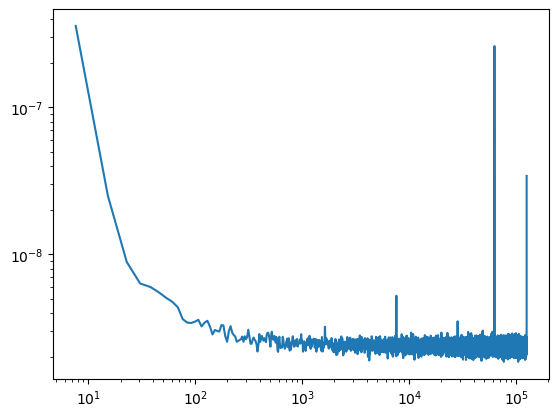

In [29]:
plt.loglog(f, Sphi)

In [33]:
f2, Sphi2, L2, info2 = phase_noise_psd_from_real(
    fibre5Ms_0, len(fibre5Ms_0)/5, f0=None, band=None  # e.g. band=(f0-1e6, f0+1e6)
)

In [35]:
f3, Sphi3, L3, info3 = phase_noise_psd_from_real(
    fibre50Ms_0, len(fibre50Ms_0)/0.5, f0=None, band=None  # e.g. band=(f0-1e6, f0+1e6)
)

In [37]:
f4, Sphi4, L4, info4 = phase_noise_psd_from_real(
    fibre500Ms_0, len(fibre500Ms_0)/0.1, f0=None, band=None  # e.g. band=(f0-1e6, f0+1e6)
)

In [43]:
%matplotlib qt

In [63]:
plt.loglog(f, Sphi)
plt.loglog(f2, Sphi2)
plt.loglog(f3, Sphi3)
plt.loglog(f4, Sphi4)

In [38]:
import MasterPSD as PSD

In [41]:
a=55
b=400
c=1762
splices=[a,b,c]

In [ ]:
dets_vs=[(det_250ks_f, det_250ks_Svv),
         (det_5Ms_f, det_5Ms_Svv),
         (det_50Ms_f, det_50Ms_Svv),
         (det_500Ms_f, det_500Ms_Svv)]

In [ ]:
dets_f, dets_Svv=PSD.SplicePSD4(dets_vs,splices)

In [49]:
import numpy as np
from scipy import signal
from scipy.signal import find_peaks

def _dphi_from_voltage(P):
    P = np.asarray(P, float).ravel()
    if P.size < 4:
        return None, "trace too short"
    S = np.nanmax(P) + np.nanmin(P)
    D = np.nanmax(P) - np.nanmin(P)
    if not np.isfinite(D) or D == 0:
        return None, "zero or NaN dynamic range"
    u = np.clip((2*P - S)/D, -1, 1)     # ≈ cos(Δφ)
    z = signal.hilbert(u)               # analytic signal
    dphi = np.unwrap(np.angle(z))
    dphi -= np.mean(dphi)
    return dphi, None

def _welch_psd(x, fs, nperseg_goal=2**15):
    N = len(x)
    if N < 8:
        return None, None, "too few samples for PSD"
    nperseg = min(int(nperseg_goal), N)
    if nperseg < 8:                     # still too short
        return None, None, "nperseg too small"
    f, S = signal.welch(x, fs=fs, window='hann',
                        nperseg=nperseg, detrend='constant',
                        scaling='density', return_onesided=True)
    # drop DC bin
    if len(f) <= 1:
        return None, None, "PSD has only DC bin"
    return f[1:], S[1:], None

def estimate_tau_from_notches_safe(P, fs, tau_guess=None):
    # Pre-check: if τ is so small that 1/τ > fs/2, notches are invisible.
    if tau_guess is not None and (1.0/tau_guess) > (fs/2):
        return np.nan, {"reason": "first notch above Nyquist; need larger τ or higher fs"}

    dphi, err = _dphi_from_voltage(P)
    if err: return np.nan, {"reason": err}

    # Aim nperseg so Δf << 1/τ if a guess is provided
    if tau_guess is not None:
        nperseg_goal = int(min(len(dphi), max(256, 12 * fs * tau_guess)))
    else:
        nperseg_goal = 2**15

    f, S, err = _welch_psd(dphi, fs, nperseg_goal)
    if err: return np.nan, {"reason": err}

    # If we don’t know τ, at least check that our resolution isn’t awful
    df = np.median(np.diff(f))
    # Smooth log-PSD safely
    S_log = np.log(np.maximum(S, np.finfo(float).tiny))
    win = min(len(S_log) - (1 - len(S_log)%2), 51)  # largest odd ≤ len(S)
    if win < 7:
        # too short to smooth; proceed unsmoothed
        S_smooth = S_log
    else:
        S_smooth = signal.savgol_filter(S_log, win, polyorder=3, mode='interp')

    # Find minima (as peaks of the inverted curve)
    peaks, _ = find_peaks(-S_smooth, distance=max(5, len(S_smooth)//200))
    if len(peaks) < 2:
        # If there are no visible notches, likely 1/τ > fs/2 or SNR/resolution too low
        # Provide diagnostic bounds
        tau_min_band = 2.0/fs                 # need τ ≥ 2/fs to place first notch ≤ fs/2
        tau_min_res  = 4.0/df                 # rough: need several bins per period
        return np.nan, {
            "reason": "fewer than two notches visible",
            "suggest": {
                "increase_record_length": "so Δf decreases (Δf≈{:.3g} Hz now)".format(df),
                "increase_tau": "so 1/τ falls below Nyquist (need τ ≥ {:.3g} s)".format(tau_min_band)
            }
        }

    fn = f[peaks]
    dfn = np.diff(fn)
    dfn = dfn[(dfn > 0) & np.isfinite(dfn)]
    if dfn.size == 0:
        return np.nan, {"reason": "could not form notch spacings"}
    df_hat = np.median(dfn)
    tau_hat = 1.0 / df_hat
    mad = np.median(np.abs(dfn - df_hat))
    tau_err = mad / (df_hat**2 + 1e-30)

    return tau_hat, {"fn": fn, "df_hat": df_hat, "tau_err_est": tau_err, "Δf": df}

In [51]:
test=estimate_tau_from_notches_safe(fibre250ks_0, len(fibre250ks_0)/20)

In [53]:
test

(0.0013107197378560524,
 {'fn': array([   167.84671326,    793.45718994,   1441.9558548 ,   2494.81251068,
           3143.31117554,   4203.79722748,   4829.40770416,   5523.68274536,
           6141.66382599,   6996.15618439,   7759.0957901 ,   8735.65848541,
           9536.74507141,  10253.90830078,  11177.06522369,  12290.95704803,
          13374.33128815,  14060.97693329,  14709.47559814,  15846.25561066,
          16937.25924683,  17631.53428802,  18730.16732025,  19447.33054962,
          20149.23498688,  20820.6218399 ,  21461.4911087 ,  22201.54252625,
          23422.24589539,  24345.4028183 ,  25161.74819641,  26374.82216949,
          27038.57962646,  27755.74285583,  28495.79427338,  29418.95119629,
          30471.80785217,  31105.04772491,  31883.24612274,  32936.10277863,
          33767.70694885,  34591.68172302,  35301.21555634,  36109.93153839,
          36819.4653717 ,  37437.44645233,  38314.8269989 ,  39291.38969421,
          40313.72876587,  40962.22743073,  41

In [55]:
test2=estimate_tau_from_notches_safe(fibre50Ms_0, len(fibre50Ms_0)/0.5)

In [57]:
test2

(6.826666393600011e-06,
 {'fn': array([   39672.85314941,  1216125.53692627,  1461792.05065918,
          1599121.15771484,  1795959.54449463,  1951599.19915771,
          2122497.64349365,  2256774.99261475,  2395629.9786377 ,
          2522277.93292236,  2676391.70861816,  2806091.4208374 ,
          2946472.28582764,  3088379.02978516,  3265380.98999023,
          3408813.61291504,  3552246.23583984,  3700256.4956665 ,
          3833007.96582031,  3959655.92010498,  4129028.48547363,
          4255676.4397583 ,  4379272.6361084 ,  4519653.50109863,
          4644775.57641602,  4771423.53070068,  4904175.00085449,
          5035400.59204102,  5168152.06219482,  5339050.50653076,
          5464172.58184814,  5615234.59960938,  5754089.58563232,
          5880737.53991699,  6008911.37316895,  6134033.44848633,
          6286621.34521484,  6417846.93640137,  6597900.65454102,
          6729126.24572754,  6872558.86865234,  7015991.49157715,
          7145691.20379639,  7279968.55291748,

In [140]:
import numpy as np
from scipy import signal

def amzi_phase_noise_from_voltage(P,fan, t, nperseg=int(1e6)):
    P = np.asarray(P, dtype=float).squeeze()
    if P.ndim != 1:
        P = P.ravel()
    fan = np.asarray(fan, dtype=float).squeeze()
    if fan.ndim != 1:
        fan = fan.ravel()

    # 1) Normalize: u = cos(Δφ)
    S = np.nanmax(fan) + np.nanmin(fan)
    D = np.nanmax(fan) - np.nanmin(fan)
    u = np.clip((2*P - S)/D, -1, 1)
    fs= len(u)/t
    # 2) Recover Δφ(t) via analytic-signal phase
    z = signal.hilbert(u)
    dphi = np.unwrap(np.angle(z))
    dphi = dphi - np.mean(dphi)

    # 3) Welch PSD of Δφ(t)  → S_Δφ [rad^2/Hz], one-sided
    f, S_dphi = signal.welch(dphi, fs, window='hann',nperseg=min(nperseg, len(dphi)))
    return f, S_dphi

In [152]:
def estimate_tau_from_notches(P,fan,t, nperseg=int(1e6)):
    P = np.asarray(P, dtype=float).squeeze()
    if P.ndim != 1:
        P = P.ravel()
    fan = np.asarray(fan, dtype=float).squeeze()
    if fan.ndim != 1:
        fan = fan.ravel()

    # 1) Normalize: u = cos(Δφ)
    S = np.nanmax(fan) + np.nanmin(fan)
    D = np.nanmax(fan) - np.nanmin(fan)
    u = np.clip((2*P - S)/D, -1, 1)
    fs= len(u)/t
    # 2) Recover Δφ(t) via analytic-signal phase
    z = signal.hilbert(u)
    dphi = np.unwrap(np.angle(z))
    dphi = dphi - np.mean(dphi)

    # 3) Welch PSD of Δφ(t)  → S_Δφ [rad^2/Hz], one-sided
    f, S = signal.welch(dphi, fs, window='hann',nperseg=min(nperseg, len(dphi)))
    # smooth a bit so minima are clearer
    S_smooth = signal.savgol_filter(np.log(S), 51, 3, mode='interp')
    # find minima as peaks of the inverted curve
    peaks, _ = find_peaks(-S_smooth, distance=max(5, len(S)//200))
    if len(peaks) < 2:
        return np.nan, {"reason": "fewer than two notches visible"}
    fn = f[peaks]
    dfn = np.diff(fn)
    # robust spacing estimate
    df_hat = np.median(dfn[(dfn > 0) & np.isfinite(dfn)])
    tau_hat = 1.0 / df_hat
    # rough uncertainty from MAD
    mad = np.median(np.abs(dfn - df_hat))
    tau_err = (mad / (df_hat**2 + 1e-30))
    return tau_hat, {"fn": fn, "df_hat": df_hat, "tau_err_est": tau_err}

In [393]:
def amzi_phase_noise_from_voltage_full2(P,fan, t,tau, nperseg=int(1e6)):
    P = np.asarray(P, dtype=float).squeeze()
    if P.ndim != 1:
        P = P.ravel()
    fan = np.asarray(fan, dtype=float).squeeze()
    if fan.ndim != 1:
        fan = fan.ravel()

    # 1) Normalize: u = cos(Δφ)
    #S = np.nanmax(fan) + np.nanmin(fan)
    #D = np.nanmax(fan) - np.nanmin(fan)
    pmin=np.nanmin(fan)
    pmax=np.nanmax(fan)
    delta = float(pmax - pmin)
    if not np.isfinite(delta) or delta <= 0:
        raise ValueError("pmax - pmin must be finite and > 0")

    u = 2.0*(P - pmin)/delta - 1.0
    # Clip to the valid domain (use a tiny epsilon to avoid hitting exactly ±1)
    eps = 1e-12
    u = np.clip(u, -1.0 + eps, 1.0 - eps)

    phi = np.arccos(u)
    #u = np.clip((2*P - S)/D, -1, 1)
    fs= len(P)/t
    # 2) Recover Δφ(t) via analytic-signal phase
    #z = signal.hilbert(u)
    #dphi = np.unwrap(np.angle(z))
    #dphi = dphi - np.mean(dphi)

    # 3) Welch PSD of Δφ(t)  → S_Δφ [rad^2/Hz], one-sided
    f, S_dphi = signal.welch(phi, fs, window='hann',nperseg=int(1e6))
    f2=f
    S_dphi2=S_dphi
    # Drop DC to avoid divide-by-zero in step 4
    f, S_dphi = f[1:], S_dphi[1:]

    # 4) Undo AMZI TF: S_φ = S_Δφ / (4 sin^2(π f τ))
    H = 4*np.sin(np.pi*f*tau)**2
    mask = H > 1e-12                       # remove notches at f≈n/τ
    S_phi = S_dphi[mask] / H[mask]
    f = f[mask]

    # 5) Extras
    L_dBc_per_Hz = 10*np.log10(0.5*S_phi)  # SSB phase noise
    S_nu = (f**2) * S_phi                   # frequency-noise PSD

    return f, S_phi, f2, S_dphi2 #L_dBc_per_Hz, S_nu

In [325]:
def amzi_phase_noise_from_voltage_full(P,fan, t,tau, nperseg=int(1e6)):
    P = np.asarray(P, dtype=float).squeeze()
    if P.ndim != 1:
        P = P.ravel()
    fan = np.asarray(fan, dtype=float).squeeze()
    if fan.ndim != 1:
        fan = fan.ravel()

    # 1) Normalize: u = cos(Δφ)
    S = np.nanmax(fan) + np.nanmin(fan)
    D = np.nanmax(fan) - np.nanmin(fan)
    u = np.clip((2*P - S)/D, -1, 1)
    fs= len(P)/t
    # 2) Recover Δφ(t) via analytic-signal phase
    z = signal.hilbert(u)
    dphi = np.unwrap(np.angle(z))
    dphi = dphi - np.mean(dphi)

    # 3) Welch PSD of Δφ(t)  → S_Δφ [rad^2/Hz], one-sided
    f, S_dphi = signal.welch(dphi, fs, window='hann',nperseg=int(1e6))
    # Drop DC to avoid divide-by-zero in step 4
    f, S_dphi = f[1:], S_dphi[1:]

    # 4) Undo AMZI TF: S_φ = S_Δφ / (4 sin^2(π f τ))
    H = 4*np.sin(np.pi*f*tau)**2
    mask = H > 1e-12                       # remove notches at f≈n/τ
    S_phi = S_dphi[mask] / H[mask]
    f = f[mask]

    # 5) Extras
    L_dBc_per_Hz = 10*np.log10(0.5*S_phi)  # SSB phase noise
    S_nu = (f**2) * S_phi                   # frequency-noise PSD

    return f, S_phi, #L_dBc_per_Hz, S_nu

In [156]:
tautest= estimate_tau_from_notches(fibre250ks_0,fibrefan_0,20)

In [158]:
tautest

(0.001312766393173673,
 {'fn': array([   388.25007765,   1058.25021165,   1769.25035385,   2411.5004823 ,
           3109.0006218 ,   4230.000846  ,   5270.001054  ,   6289.75125795,
           6928.75138575,   7554.5015109 ,   8778.25175565,   9404.25188085,
          10583.75211675,  11209.0022418 ,  11898.0023796 ,  12764.25255285,
          14008.0028016 ,  15139.25302785,  16138.25322765,  17146.0034292 ,
          17907.75358155,  19027.5038055 ,  19838.75396775,  20841.5041683 ,
          21485.5042971 ,  22167.0044334 ,  22817.25456345,  23471.0046942 ,
          24420.004884  ,  25084.5050169 ,  25732.0051464 ,  26478.25529565,
          27644.75552895,  28634.0057268 ,  29455.75589115,  30380.25607605,
          31421.5062843 ,  32382.5064765 ,  33279.25665585,  33910.5067821 ,
          35081.25701625,  35800.00716   ,  36551.25731025,  37288.0074576 ,
          37920.5075841 ,  38545.75770915,  39301.5078603 ,  40032.75800655,
          40826.5081653 ,  41808.0083616 ,  427

In [180]:
tautest2= estimate_tau_from_notches(fibre500Ms_0,fibrefan_0,0.1)

In [182]:
tautest2

(6.455777663008401e-07,
 {'fn': array([4.18000017e+05, 1.74400007e+06, 3.53050014e+06, 5.00550020e+06,
         6.53850026e+06, 7.82450031e+06, 9.50650038e+06, 1.17705005e+07,
         1.35720005e+07, 1.56370006e+07, 1.75820007e+07, 1.96365008e+07,
         2.14765009e+07, 2.32920009e+07, 2.48225010e+07, 2.60845010e+07,
         2.73360011e+07, 2.88850012e+07, 3.12380012e+07, 3.32315013e+07,
         3.50715014e+07, 3.63720015e+07, 3.76910015e+07, 3.90745016e+07,
         4.14070017e+07, 4.29920017e+07, 4.54425018e+07, 4.68870019e+07,
         4.82315019e+07, 4.97855020e+07, 5.10485020e+07, 5.31635021e+07,
         5.46755022e+07, 5.60335022e+07, 5.83385023e+07, 5.96185024e+07,
         6.08970024e+07, 6.25120025e+07, 6.42755026e+07, 6.62000026e+07,
         6.85090027e+07, 7.03005028e+07, 7.21140029e+07, 7.45465030e+07,
         7.60450030e+07, 7.81370031e+07, 7.94995032e+07, 8.10335032e+07,
         8.33300033e+07, 8.45855034e+07, 8.59495034e+07, 8.73885035e+07,
         8.95755036e+

In [74]:
fibrefan_0

[0.018833516,
 0.018926442,
 0.018624432,
 0.018717358,
 0.018926442,
 0.018926442,
 0.018833516,
 0.019158758,
 0.018787053,
 0.018787053,
 0.018856748,
 0.018926442,
 0.018694127,
 0.019228452,
 0.018763821,
 0.018717358,
 0.018903211,
 0.018949674,
 0.018926442,
 0.018461811,
 0.01874059,
 0.018647664,
 0.018531506,
 0.019065831,
 0.018601201,
 0.018577969,
 0.018368885,
 0.018647664,
 0.018670895,
 0.018996137,
 0.018577969,
 0.018531506,
 0.018694127,
 0.018833516,
 0.018624432,
 0.018996137,
 0.018554738,
 0.018717358,
 0.018461811,
 0.018949674,
 0.0190426,
 0.018624432,
 0.018833516,
 0.018717358,
 0.018717358,
 0.018531506,
 0.018787053,
 0.018577969,
 0.018508275,
 0.018345654,
 0.018531506,
 0.018461811,
 0.018647664,
 0.018694127,
 0.018624432,
 0.018322422,
 0.01813657,
 0.01874059,
 0.018577969,
 0.018763821,
 0.018717358,
 0.018624432,
 0.018299191,
 0.018415348,
 0.018554738,
 0.018554738,
 0.018554738,
 0.018717358,
 0.018392117,
 0.018647664,
 0.018647664,
 0.01876382

In [142]:
ftest, stest = amzi_phase_noise_from_voltage(fibre250ks_0,fibrefan_0,20)

In [143]:
ftest2, stest2 = amzi_phase_noise_from_voltage(fibre5Ms_0,fibrefan_0,5)

In [144]:
ftest3, stest3 = amzi_phase_noise_from_voltage(fibre50Ms_0,fibrefan_0,0.5)

In [145]:
ftest4, stest4 = amzi_phase_noise_from_voltage(fibre500Ms_0,fibrefan_0,0.1)

In [210]:
f1, s1 = amzi_phase_noise_from_voltage_full(fibre250ks_0,fibre250ks_0,20,6.455777663008401e-07)

In [211]:
f2, s2 = amzi_phase_noise_from_voltage_full(fibre5Ms_0,fibre5Ms_0,5,6.455777663008401e-07)

In [212]:
f3, s3 = amzi_phase_noise_from_voltage_full(fibre50Ms_0,fibrefan_0,0.5,6.455777663008401e-07)

In [213]:
f4, s4 = amzi_phase_noise_from_voltage_full(fibre500Ms_0,fibrefan_0,0.1,6.455777663008401e-07)

In [123]:
ftest

array([0.00000000e+00, 2.50000050e-01, 5.00000100e-01, ...,
       1.24999525e+05, 1.24999775e+05, 1.25000025e+05])

In [150]:
plt.loglog(ftest,stest)
plt.loglog(ftest2,stest2)
plt.loglog(ftest3,stest3)
plt.loglog(ftest4,stest4)

In [226]:
plt.loglog(f1,s1)
plt.loglog(f2,s2)
plt.loglog(f3,s3)
plt.loglog(f4,s4)

In [3]:
from scipy.signal import find_peaks
import numpy as np

# f, S_phi are your de-embedded results
# find spikes (peaks) on log scale
f=f1
S_phi=s1
y = np.log(np.maximum(S_phi, np.finfo(float).tiny))
pk, _ = find_peaks(y, distance=max(5, len(y)//500), prominence=1.0)
fn = f[pk]                                  # spike freqs
df = np.diff(fn)
tau_hat = 1/np.median(df[df>0])
print("τ from spike spacing:", tau_hat, "s  (FSR ≈", 1/tau_hat, "Hz)")

NameError: name 'f1' is not defined

In [218]:
f=f2
S_phi=s2
y = np.log(np.maximum(S_phi, np.finfo(float).tiny))
pk, _ = find_peaks(y, distance=max(5, len(y)//500), prominence=1.0)
fn = f[pk]                                  # spike freqs
df = np.diff(fn)
tau_hat = 1/np.median(df[df>0])
print("τ from spike spacing:", tau_hat, "s  (FSR ≈", 1/tau_hat, "Hz)")

τ from spike spacing: 0.00012110202361489428 s  (FSR ≈ 8257.5003303001 Hz)


In [219]:
f=f3
S_phi=s3
y = np.log(np.maximum(S_phi, np.finfo(float).tiny))
pk, _ = find_peaks(y, distance=max(5, len(y)//500), prominence=1.0)
fn = f[pk]                                  # spike freqs
df = np.diff(fn)
tau_hat = 1/np.median(df[df>0])
print("τ from spike spacing:", tau_hat, "s  (FSR ≈", 1/tau_hat, "Hz)")

τ from spike spacing: 5.08194618218776e-06 s  (FSR ≈ 196775.00787100103 Hz)


In [220]:
f=f4
S_phi=s4
y = np.log(np.maximum(S_phi, np.finfo(float).tiny))
pk, _ = find_peaks(y, distance=max(5, len(y)//500), prominence=1.0)
fn = f[pk]                                  # spike freqs
df = np.diff(fn)
tau_hat = 1/np.median(df[df>0])
print("τ from spike spacing:", tau_hat, "s  (FSR ≈", 1/tau_hat, "Hz)")

τ from spike spacing: 6.455777663008478e-07 s  (FSR ≈ 1549000.061959982 Hz)


In [229]:
DM250ks_1_Z5_0=np.load('DM250ks_1_Z5.npy').tolist()
DM5Ms_1_Z5_0=np.load('DM5Ms_1_Z5.npy').tolist()
DM50Ms_1_Z5_0=np.load('DM50Ms_1_Z5.npy').tolist()
DM500Ms_1_Z5_0=np.load('DM500Ms_1_Z5.npy').tolist()
DMfan_1_Z5_0=np.load('DMfan_1_Z5.npy').tolist()

In [231]:
tautest2= estimate_tau_from_notches(DM500Ms_1_Z5_0,DMfan_1_Z5_0,0.1)

In [233]:
tautest2

(6.565988049901512e-07,
 {'fn': array([2.82500006e+05, 1.55450003e+06, 3.93650008e+06, 5.77300012e+06,
         7.02300014e+06, 8.39800017e+06, 1.06240002e+07, 1.24605002e+07,
         1.38045003e+07, 1.56370003e+07, 1.76795004e+07, 1.94675004e+07,
         2.08670004e+07, 2.21240004e+07, 2.34255005e+07, 2.49365005e+07,
         2.63425005e+07, 2.85550006e+07, 3.08985006e+07, 3.21800006e+07,
         3.34675007e+07, 3.50235007e+07, 3.64630007e+07, 3.77740008e+07,
         3.90745008e+07, 4.03885008e+07, 4.21675008e+07, 4.34870009e+07,
         4.51250009e+07, 4.68870009e+07, 4.88510010e+07, 5.06995010e+07,
         5.19715010e+07, 5.32230011e+07, 5.46755011e+07, 5.61230011e+07,
         5.74070011e+07, 5.87820012e+07, 6.06305012e+07, 6.25120013e+07,
         6.38440013e+07, 6.52445013e+07, 6.71560013e+07, 6.87460014e+07,
         7.03005014e+07, 7.16485014e+07, 7.36235015e+07, 7.50025015e+07,
         7.63760015e+07, 7.81130016e+07, 8.05135016e+07, 8.17945016e+07,
         8.38900017e+

In [235]:
f_1_Z5, SPhi_1_Z5 = amzi_phase_noise_from_voltage_full(DM250ks_1_Z5_0,DMfan_1_Z5_0,20,6.565988049901512e-07)
f_2_Z5, SPhi_2_Z5 = amzi_phase_noise_from_voltage_full(DM5Ms_1_Z5_0,DMfan_1_Z5_0,5,6.565988049901512e-07)
f_3_Z5, SPhi_3_Z5 = amzi_phase_noise_from_voltage_full(DM50Ms_1_Z5_0,DMfan_1_Z5_0,0.5,6.565988049901512e-07)
f_4_Z5, SPhi_4_Z5 = amzi_phase_noise_from_voltage_full(DM500Ms_1_Z5_0,DMfan_1_Z5_0,0.1,6.565988049901512e-07)

In [241]:
plt.loglog(f_1_Z5, SPhi_1_Z5)
plt.loglog(f_2_Z5, SPhi_2_Z5)
plt.loglog(f_3_Z5, SPhi_3_Z5)
plt.loglog(f_4_Z5, SPhi_4_Z5)

In [243]:
splices=[200,1200,18000]

In [245]:
z5s=[(f_1_Z5, SPhi_1_Z5),
     (f_2_Z5, SPhi_2_Z5),
     (f_3_Z5, SPhi_3_Z5),
     (f_4_Z5, SPhi_4_Z5)]

In [247]:
z5_f, z5_SPhi=PSD.SplicePSD4(z5s,splices)

In [253]:
plt.loglog(z5_f, z5_SPhi)

In [27]:
DM250ks_AOMoff_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM250ks_AOMoff_3.npy').tolist()
DM5Ms_AOMoff_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM5Ms_AOMoff_3.npy').tolist()
DM50Ms_AOMoff_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM50Ms_AOMoff_3.npy').tolist()
DM500Ms_AOMoff_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM500Ms_AOMoff_3.npy').tolist()
DMfan_AOMoff_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DMfan_AOMoff_3.npy').tolist()

In [256]:
DM250ks_AOMON_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM250ks_AOMON_3.npy').tolist()
DM5Ms_AOMON_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM5Ms_AOMON_3.npy').tolist()
DM50Ms_AOMON_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM50Ms_AOMON_3.npy').tolist()
DM500Ms_AOMON_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DM500Ms_AOMON_3.npy').tolist()
DMfan_AOMON_3 = np.load(r'C:\Users\Ry\Documents\COATposterwork\DMfan_AOMON_3.npy').tolist()

In [293]:
tautest3= estimate_tau_from_notches(DMfan_AOMoff_3,DMfan_AOMoff_3,0.1)
tautest4= estimate_tau_from_notches(DM500Ms_AOMON_3,DMfan_AOMON_3,0.1)

KeyboardInterrupt: 

In [294]:
tautest3= estimate_tau_from_notches(DMfan_AOMoff_3,DMfan_AOMoff_3,20)


In [296]:
tautest3

(0.0012783634387983807,
 {'fn': array([   412.5000825 ,   1223.25024465,   1876.5003753 ,   2506.0005012 ,
           3133.0006266 ,   3812.0007624 ,   4613.75092275,   5739.25114785,
           6416.0012832 ,   7566.0015132 ,   8669.25173385,   9700.25194005,
          10476.0020952 ,  11135.75222715,  12189.0024378 ,  13364.0026728 ,
          14292.25285845,  15153.5030307 ,  16303.75326075,  16932.5033865 ,
          17561.25351225,  18654.75373095,  19325.75386515,  20373.0040746 ,
          21011.25420225,  22117.0044234 ,  22985.5045971 ,  23635.004727  ,
          24575.75491515,  25359.75507195,  26140.5052281 ,  26851.25537025,
          27561.75551235,  28563.5057127 ,  29260.75585215,  30112.5060225 ,
          31340.75626815,  32230.75644615,  33258.75665175,  33974.0067948 ,
          34857.75697155,  35881.75717635,  36546.5073093 ,  37345.5074691 ,
          38096.0076192 ,  38898.5077797 ,  39610.75792215,  40298.75805975,
          40958.0081916 ,  41606.25832125,  42

In [280]:
tautest4

(5.329069970690103e-07,
 {'fn': array([6.14000012e+05, 1.86500004e+06, 3.74150007e+06, 5.61800011e+06,
         7.51900015e+06, 9.70150019e+06, 1.15780002e+07, 1.32440003e+07,
         1.45345003e+07, 1.59185003e+07, 1.74895003e+07, 1.88765004e+07,
         2.02235004e+07, 2.15730004e+07, 2.29570005e+07, 2.43570005e+07,
         2.56075005e+07, 2.72030005e+07, 2.93610006e+07, 3.12380006e+07,
         3.31145007e+07, 3.49915007e+07, 3.68925007e+07, 3.84440008e+07,
         4.06460008e+07, 4.19145008e+07, 4.34865009e+07, 4.49860009e+07,
         4.68080009e+07, 4.87640010e+07, 5.06165010e+07, 5.21165010e+07,
         5.34235011e+07, 5.46995011e+07, 5.59895011e+07, 5.75030012e+07,
         5.88190012e+07, 6.06355012e+07, 6.28360013e+07, 6.43645013e+07,
         6.58020013e+07, 6.70635013e+07, 6.84235014e+07, 7.00195014e+07,
         7.17960014e+07, 7.42920015e+07, 7.62605015e+07, 7.81370016e+07,
         7.95470016e+07, 8.08885016e+07, 8.22185016e+07, 8.40730017e+07,
         8.59495017e+

In [335]:
tau=6.597393897410507e-07

In [395]:
f_1_ON, SPhi_1_ON, x1, y1 = amzi_phase_noise_from_voltage_full2(DM250ks_AOMON_3,DMfan_AOMoff_3,20,tau)
f_2_ON, SPhi_2_ON, x2, y2 = amzi_phase_noise_from_voltage_full2(DM5Ms_AOMON_3,DMfan_AOMoff_3,5,tau)
f_3_ON, SPhi_3_ON, x3, y3 = amzi_phase_noise_from_voltage_full2(DM50Ms_AOMON_3,DMfan_AOMoff_3,0.5,tau)
f_4_ON, SPhi_4_ON, x4, y4 = amzi_phase_noise_from_voltage_full2(DM500Ms_AOMON_3,DMfan_AOMoff_3,0.1,tau)

In [327]:
tau2=6.302189884985023e-07
#tau2=1.2799999744000005e-07

In [369]:
f_1_off, SPhi_1_off = amzi_phase_noise_from_voltage_full2(DM250ks_AOMoff_3,DMfan_AOMoff_3,20,tau2)
f_2_off, SPhi_2_off = amzi_phase_noise_from_voltage_full2(DM5Ms_AOMoff_3,DMfan_AOMoff_3,5,tau2)
f_3_off, SPhi_3_off = amzi_phase_noise_from_voltage_full2(DM50Ms_AOMoff_3,DMfan_AOMoff_3,0.5,tau2)
f_4_off, SPhi_4_off = amzi_phase_noise_from_voltage_full2(DM500Ms_AOMoff_3,DMfan_AOMoff_3,0.1,tau2)

In [397]:
plt.loglog(f_1_ON, SPhi_1_ON)
plt.loglog(f_2_ON, SPhi_2_ON)
plt.loglog(f_3_ON, SPhi_3_ON)
plt.loglog(f_4_ON, SPhi_4_ON)

In [399]:
plt.loglog(x1, y1)
plt.loglog(x2, y2)
plt.loglog(x3, y3)
plt.loglog(x4, y4)

In [371]:
plt.loglog(f_1_off, SPhi_1_off)
plt.loglog(f_2_off, SPhi_2_off)
plt.loglog(f_3_off, SPhi_3_off)
plt.loglog(f_4_off, SPhi_4_off)

In [303]:

def estimate_tau_via_cepstrum(P,fan, t, nperseg=2**15, qmin=None, qmax=None):
    P = np.asarray(P, dtype=float).squeeze()
    if P.ndim != 1:
        P = P.ravel()
    fan = np.asarray(fan, dtype=float).squeeze()
    if fan.ndim != 1:
        fan = fan.ravel()

    # 1) Normalize: u = cos(Δφ)
    S = np.nanmax(fan) + np.nanmin(fan)
    D = np.nanmax(fan) - np.nanmin(fan)
    u = np.clip((2*P - S)/D, -1, 1)
    fs= len(P)/t
    # 2) Recover Δφ(t) via analytic-signal phase
    z = signal.hilbert(u)
    dphi = np.unwrap(np.angle(z))
    dphi = dphi - np.mean(dphi)

    # 3) Welch PSD of Δφ(t)  → S_Δφ [rad^2/Hz], one-sided
    f, S = signal.welch(dphi, fs, window='hann',nperseg=min(nperseg, len(dphi)))
    # real cepstrum of log spectrum
    L = np.log(np.maximum(S, np.finfo(float).tiny))
    C = np.fft.irfft(L, n=len(L)*2-2)          # quefrency grid step ≈ 1/(max f)
    q = np.arange(len(C)) / (f[-1]*2)          # seconds
    # search window
    if qmin is None: qmin = 1.0/(f[-1])        # one period at highest freq
    if qmax is None: qmax = 0.5/np.diff(f).mean() # ~record length
    m = (q >= qmin) & (q <= qmax)
    if not np.any(m):
        return np.nan, {"reason": "empty search range"}
    k = np.argmax(C[m])
    tau_hat = q[m][k]
    return tau_hat, {"q": q, "C": C, "search_mask": m}

In [305]:
testing5=estimate_tau_via_cepstrum(DM500Ms_AOMoff_3,DMfan_AOMoff_3,0.1)

In [307]:
testing5

(1.2799999744000005e-07,
 {'q': array([0.00000000e+00, 1.99999996e-09, 3.99999992e-09, ...,
         6.55299987e-05, 6.55319987e-05, 6.55339987e-05]),
  'C': array([-2.75661940e+01,  8.69725632e-03,  9.53266501e-03, ...,
          6.85284562e-03,  9.53266501e-03,  8.69725632e-03]),
  'search_mask': array([False, False,  True, ..., False, False, False])})

In [341]:
ON=[(f_1_ON, SPhi_1_ON),
     (f_2_ON, SPhi_2_ON),
     (f_3_ON, SPhi_3_ON),
     (f_4_ON, SPhi_4_ON)]

In [401]:
ON2=[(x1, y1),
     (x2, y2),
     (x3, y3),
     (x4, y4)]

In [373]:
offs=[(f_1_off, SPhi_1_off),
     (f_2_off, SPhi_2_off),
     (f_3_off, SPhi_3_off),
     (f_4_off, SPhi_4_off)]

In [375]:
splices=[50,976,5100]

In [377]:
ON_f, ON_SPhi=PSD.SplicePSD4(ON,splices)

In [403]:
ON2_f, ON2_SPhi=PSD.SplicePSD4(ON2,splices)

In [379]:
off_f, off_SPhi=PSD.SplicePSD4(offs,splices)

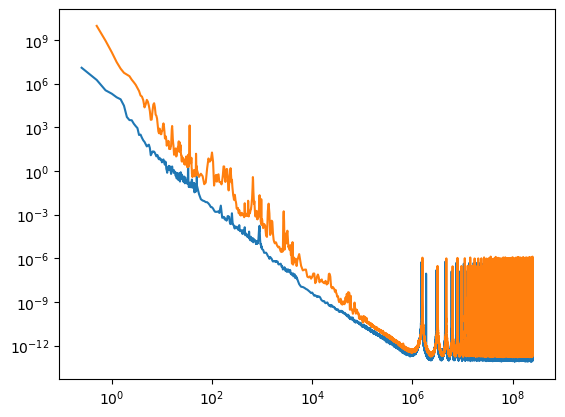

In [17]:
plt.loglog(ON_f, ON_SPhi)
plt.loglog(off_f, off_SPhi)

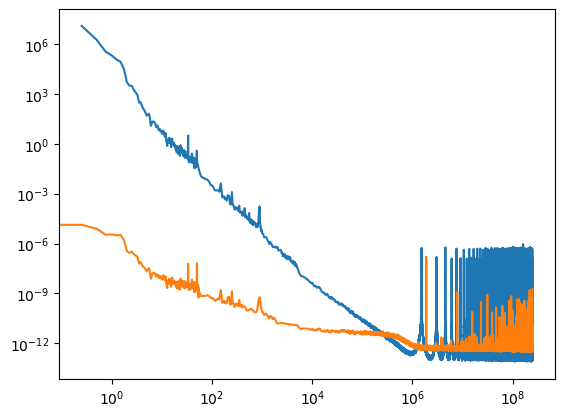

In [19]:
plt.loglog(ON_f, ON_SPhi)
#plt.loglog(ON2_f, ON2_SPhi)
plt.loglog(AOMON_0_3_x, AOMON_0_3_y)

In [383]:
np.save("ON_f.npy",ON_f)
np.save("ON_SPhi.npy", ON_SPhi)
np.save("off_f.npy", off_f)
np.save("off_SPhi.npy", off_SPhi)

In [7]:
AOMoff_3_x, AOMoff_3_y = np.load('AOMoff_3_x.npy'), np.load('AOMoff_3_y.npy')
AOMON_0_3_x, AOMON_0_3_y = np.load('AOMON_0_3_x.npy'), np.load('AOMON_0_3_y.npy')

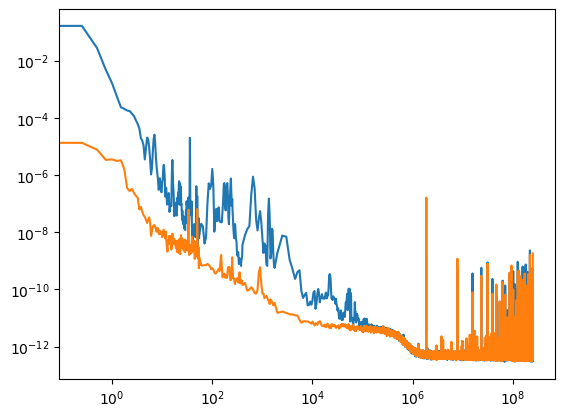

In [13]:
plt.loglog(AOMoff_3_x, AOMoff_3_y)
plt.loglog(AOMON_0_3_x, AOMON_0_3_y)

In [5]:
ON_f=np.load("ON_f.npy")
ON_SPhi=np.load("ON_SPhi.npy")
off_f=np.load("off_f.npy")
off_SPhi=np.load("off_SPhi.npy")

In [11]:
from matplotlib import pyplot as plt

In [21]:
def PSDanalysis(list2, list3, t):
    # Convert to numpy arrays
    list2 = np.asarray(list2)
    list3 = np.asarray(list3)

    # Assume 1D, get first column
    list2_vals = list2[:, 0] if list2.ndim > 1 else list2
    list3_vals = list3[:, 0] if list3.ndim > 1 else list3

    S = np.max(list3_vals) + np.min(list3_vals)
    D = np.max(list3_vals) - np.min(list3_vals)

    x = ((2 * list2_vals) - S) / D

    # Clip and count
    x_clipped = np.clip(x, -1, 1)
    count = np.sum((x > 1) | (x < -1))

    fs = len(x_clipped) / t
    f, Pxx_den = signal.welch(x_clipped, fs, window='hann', nperseg=int(1e6))

    print(count)
    return f, Pxx_den

In [33]:
def PSDanalysisFIX(list2, list3, t):
    # Convert to numpy arrays
    list2 = np.asarray(list2)
    list3 = np.asarray(list3)

    # Assume 1D, get first column
    list2_vals = list2[:, 0] if list2.ndim > 1 else list2
    list3_vals = list3[:, 0] if list3.ndim > 1 else list3

    S = np.max(list3_vals) + np.min(list3_vals)
    D = np.max(list3_vals) - np.min(list3_vals)

    x = ((2 * list2_vals) - S) / D
    # Clip and count
    x_clipped = np.clip(x, -1, 1)
    count = np.sum((x > 1) | (x < -1))
    phi=np.arccos(x_clipped)
    fs = len(x_clipped) / t
    f, Pxx_den = signal.welch(phi, fs, window='hann', nperseg=int(1e6))

    print(count)
    return f, Pxx_den

In [102]:
def PSDanalysisFIX2(list2, list3, t):
    # Convert to numpy arrays
    list2 = np.asarray(list2)
    list3 = np.asarray(list3)

    # Assume 1D, get first column
    list2_vals = list2[:, 0] if list2.ndim > 1 else list2
    list3_vals = list3[:, 0] if list3.ndim > 1 else list3

    S = np.max(list3_vals) + np.min(list3_vals)
    D = np.max(list3_vals) - np.min(list3_vals)

    x = ((2 * list2_vals) - S) / D
    # Clip and count
    x_clipped = np.clip(x, -1, 1)
    count = np.sum((x > 1) | (x < -1))
    z = signal.hilbert(x_clipped)
    dphi = np.unwrap(np.angle(z))
    dphi -= np.mean(dphi)
    fs = len(x_clipped) / t
    f, Pxx_den = signal.welch(dphi, fs, window='hann', nperseg=int(1e6))

    print(count)
    return f[1:], Pxx_den[1:]

In [29]:
f_1_off1, SPhi_1_off1 = PSDanalysis(DM250ks_AOMoff_3,DMfan_AOMoff_3,20)
f_2_off1, SPhi_2_off1 = PSDanalysis(DM5Ms_AOMoff_3,DMfan_AOMoff_3,5)
f_3_off1, SPhi_3_off1 = PSDanalysis(DM50Ms_AOMoff_3,DMfan_AOMoff_3,0.5)
f_4_off1, SPhi_4_off1 = PSDanalysis(DM500Ms_AOMoff_3,DMfan_AOMoff_3,0.1)

0
125
0
0


In [35]:
f_1_off2, SPhi_1_off2 = PSDanalysisFIX(DM250ks_AOMoff_3,DMfan_AOMoff_3,20)
f_2_off2, SPhi_2_off2 = PSDanalysisFIX(DM5Ms_AOMoff_3,DMfan_AOMoff_3,5)
f_3_off2, SPhi_3_off2 = PSDanalysisFIX(DM50Ms_AOMoff_3,DMfan_AOMoff_3,0.5)
f_4_off2, SPhi_4_off2 = PSDanalysisFIX(DM500Ms_AOMoff_3,DMfan_AOMoff_3,0.1)

0
125
0
0


In [104]:
f_1_off3, SPhi_1_off3 = PSDanalysisFIX2(DM250ks_AOMoff_3,DMfan_AOMoff_3,20)
f_2_off3, SPhi_2_off3 = PSDanalysisFIX2(DM5Ms_AOMoff_3,DMfan_AOMoff_3,5)
f_3_off3, SPhi_3_off3 = PSDanalysisFIX2(DM50Ms_AOMoff_3,DMfan_AOMoff_3,0.5)
f_4_off3, SPhi_4_off3 = PSDanalysisFIX2(DM500Ms_AOMoff_3,DMfan_AOMoff_3,0.1)

0
125
0
0


In [128]:
f_1_off4, SPhi_1_off4 = PSDanalysisFIX(DM250ks_AOMoff_3,DMfan_AOMoff_3,20)
f_2_off4, SPhi_2_off4 = PSDanalysisFIX(DM5Ms_AOMoff_3,DMfan_AOMoff_3,5)
f_3_off4, SPhi_3_off4 = PSDanalysisFIX(DM50Ms_AOMoff_3,DMfan_AOMoff_3,0.5)
f_4_off4, SPhi_4_off4 = PSDanalysisFIX(DM500Ms_AOMoff_3,DMfan_AOMoff_3,0.1)

0
125
0
0


In [37]:
import MasterPSD as PSD

In [39]:
offs1=[(f_1_off1, SPhi_1_off1),
     (f_2_off1, SPhi_2_off1),
     (f_3_off1, SPhi_3_off1),
     (f_4_off1, SPhi_4_off1)]

In [41]:
offs2=[(f_1_off2, SPhi_1_off2),
     (f_2_off2, SPhi_2_off2),
     (f_3_off2, SPhi_3_off2),
     (f_4_off2, SPhi_4_off2)]

In [112]:
offs3=[(f_1_off3, SPhi_1_off3),
     (f_2_off3, SPhi_2_off3),
     (f_3_off3, SPhi_3_off3),
     (f_4_off3, SPhi_4_off3)]

In [130]:
offs4=[(f_1_off4, SPhi_1_off4),
     (f_2_off4, SPhi_2_off4),
     (f_3_off4, SPhi_3_off4),
     (f_4_off4, SPhi_4_off4)]

In [138]:
plt.loglog(f_1_off1, SPhi_1_off1)
plt.loglog(f_1_off2, SPhi_1_off2)
#plt.loglog(f_1_off3, SPhi_1_off3)
plt.loglog(f_1_off4, SPhi_1_off4)

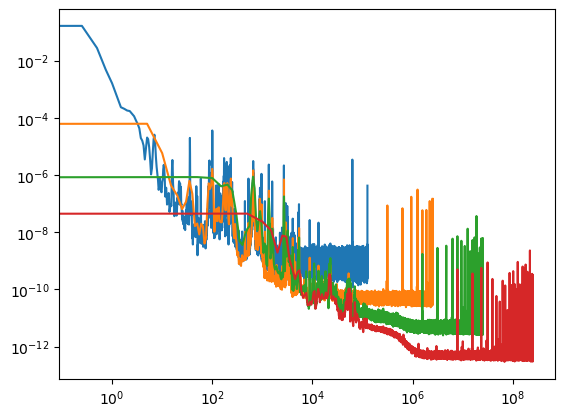

In [57]:
plt.loglog(f_1_off1, SPhi_1_off1)
plt.loglog(f_2_off1, SPhi_2_off1)
plt.loglog(f_3_off1, SPhi_3_off1)
plt.loglog(f_4_off1, SPhi_4_off1)


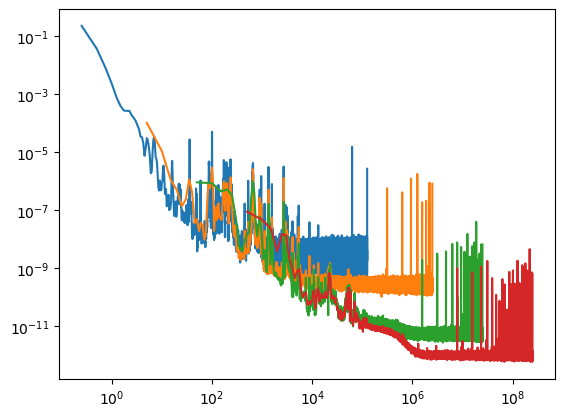

In [118]:
plt.loglog(f_1_off3, SPhi_1_off3)
plt.loglog(f_2_off3, SPhi_2_off3)
plt.loglog(f_3_off3, SPhi_3_off3)
plt.loglog(f_4_off3, SPhi_4_off3)

In [88]:
splices=[50,976,5100]

In [61]:
off_f1, off_SPhi1=PSD.SplicePSD4(offs1,splices)

In [80]:
off_f2, off_SPhi2=PSD.SplicePSD4(offs2,splices)

In [114]:
off_f3, off_SPhi3=PSD.SplicePSD4(offs3,splices)

In [124]:
%matplotlib qt

In [126]:
plt.loglog(off_f1, off_SPhi1)
plt.loglog(off_f2, off_SPhi2)
plt.loglog(off_f3, off_SPhi3)